# PriceFusion V0.5 — Structured & Hybrid Modeling

**Project:** PriceFusion — Multimodal Product Price Intelligence  
**Stage:** V0.5  
**Goal:** Train strong structured models on V0.4.1 features and test whether they improve upon or complement the V0.3 TF-IDF baseline.

This notebook will:
- load hardened V0.4.1 parquet features
- reuse the permanent 60K/15K V0.3 split
- train CatBoost on raw and log targets
- train LightGBM on log target
- evaluate SMAPE, MAE, and bucket performance
- reload V0.3 text validation predictions
- test structured + text weighted ensembles
- save models, metrics, ensemble config, and validation predictions


## 1. Imports

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, median_absolute_error

from catboost import CatBoostRegressor
import lightgbm as lgb

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 200)
pd.set_option('display.max_colwidth', 180)

RANDOM_STATE = 42
print('V0.5 environment ready.')

V0.5 environment ready.


## 2. Resolve Project Paths

In [2]:
cwd = Path.cwd().resolve()

if (cwd / 'dataset').exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / 'dataset').exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError('Could not find project root.')

ARTIFACTS_DIR = PROJECT_ROOT / 'artifacts'
FEATURES_DIR = ARTIFACTS_DIR / 'features'
METRICS_DIR = ARTIFACTS_DIR / 'metrics'
PREDICTIONS_DIR = ARTIFACTS_DIR / 'predictions'
FIGURES_DIR = ARTIFACTS_DIR / 'figures'
MODELS_DIR = PROJECT_ROOT / 'models' / 'v05_structured_hybrid'

for p in [METRICS_DIR, PREDICTIONS_DIR, FIGURES_DIR, MODELS_DIR]:
    p.mkdir(parents=True, exist_ok=True)

TRAIN_FEATURES_PATH = FEATURES_DIR / 'v04_train_features.parquet'
VALID_FEATURES_PATH = FEATURES_DIR / 'v04_validation_features.parquet'
TEST_FEATURES_PATH = FEATURES_DIR / 'v04_test_features.parquet'
TEXT_PREDS_PATH = PREDICTIONS_DIR / 'v03_validation_predictions.csv'

print('Project root:', PROJECT_ROOT)
print('Models dir  :', MODELS_DIR)

Project root: /Users/sagnikdey/Desktop/PROJECTS/AIML/PriceFusion
Models dir  : /Users/sagnikdey/Desktop/PROJECTS/AIML/PriceFusion/models/v05_structured_hybrid


## 3. Load V0.4.1 Features

In [3]:
train_df = pd.read_parquet(TRAIN_FEATURES_PATH)
valid_df = pd.read_parquet(VALID_FEATURES_PATH)
test_df = pd.read_parquet(TEST_FEATURES_PATH)

print('Train:', train_df.shape)
print('Valid:', valid_df.shape)
print('Test :', test_df.shape)

assert 'price' in train_df.columns
assert 'price' in valid_df.columns
assert 'price' not in test_df.columns

Train: (60000, 59)
Valid: (15000, 59)
Test : (75000, 58)


## 4. Evaluation Functions

In [4]:
def smape(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    denom = (np.abs(y_true) + np.abs(y_pred)) / 2.0
    num = np.abs(y_true - y_pred)
    ratio = np.divide(num, denom, out=np.zeros_like(num), where=denom != 0)
    return float(np.mean(ratio) * 100.0)

def clip_positive(pred):
    return np.maximum(np.asarray(pred, dtype=float), 0.01)

def evaluate(y_true, y_pred, model_name):
    y_pred = clip_positive(y_pred)
    return {
        'model': model_name,
        'smape': smape(y_true, y_pred),
        'mae': mean_absolute_error(y_true, y_pred),
        'median_ae': median_absolute_error(y_true, y_pred),
        'min_prediction': float(y_pred.min()),
        'max_prediction': float(y_pred.max()),
    }

def show_metrics(m):
    print(m['model'])
    print(f"SMAPE     : {m['smape']:.4f}%")
    print(f"MAE       : {m['mae']:.4f}")
    print(f"Median AE : {m['median_ae']:.4f}")

## 5. Prepare Features

In [5]:
TARGET = 'price'
ID_COL = 'sample_id'
CAT_COLS = ['unit_normalized']

feature_cols = [c for c in train_df.columns if c not in {TARGET, ID_COL}]

X_train = train_df[feature_cols].copy()
X_valid = valid_df[feature_cols].copy()
X_test = test_df[feature_cols].copy()

y_train = train_df[TARGET].values
y_valid = valid_df[TARGET].values

for col in CAT_COLS:
    X_train[col] = X_train[col].fillna('unknown').astype(str)
    X_valid[col] = X_valid[col].fillna('unknown').astype(str)
    X_test[col] = X_test[col].fillna('unknown').astype(str)

numeric_cols = [c for c in feature_cols if c not in CAT_COLS]
for col in numeric_cols:
    X_train[col] = pd.to_numeric(X_train[col], errors='coerce')
    X_valid[col] = pd.to_numeric(X_valid[col], errors='coerce')
    X_test[col] = pd.to_numeric(X_test[col], errors='coerce')

print('Feature count:', len(feature_cols))
print('Categorical columns:', CAT_COLS)

Feature count: 57
Categorical columns: ['unit_normalized']


## 6. CatBoost — Raw Price Target

In [6]:
results = []
predictions = {}

cat_raw = CatBoostRegressor(
    iterations=1500,
    learning_rate=0.035,
    depth=8,
    loss_function='MAE',
    eval_metric='MAE',
    random_seed=RANDOM_STATE,
    verbose=100,
    allow_writing_files=False,
)

cat_raw.fit(
    X_train,
    y_train,
    cat_features=CAT_COLS,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=100,
    verbose=100,
)

cat_raw_pred = clip_positive(cat_raw.predict(X_valid))
m = evaluate(y_valid, cat_raw_pred, 'CatBoost Structured (Raw Price)')
results.append(m)
predictions['cat_raw'] = cat_raw_pred
show_metrics(m)

0:	learn: 16.4729217	test: 16.1076263	best: 16.1076263 (0)	total: 72.9ms	remaining: 1m 49s
100:	learn: 13.1102910	test: 13.0176200	best: 13.0176200 (100)	total: 1.42s	remaining: 19.7s
200:	learn: 12.6037866	test: 12.6403878	best: 12.6403878 (200)	total: 2.96s	remaining: 19.1s
300:	learn: 12.2895909	test: 12.4557265	best: 12.4557265 (300)	total: 4.2s	remaining: 16.7s
400:	learn: 12.0336331	test: 12.3252347	best: 12.3252347 (400)	total: 5.43s	remaining: 14.9s
500:	learn: 11.8256837	test: 12.2337319	best: 12.2337319 (500)	total: 6.69s	remaining: 13.3s
600:	learn: 11.6570815	test: 12.1588824	best: 12.1588824 (600)	total: 8.01s	remaining: 12s
700:	learn: 11.4984311	test: 12.1062577	best: 12.1062577 (700)	total: 9.75s	remaining: 11.1s
800:	learn: 11.3599365	test: 12.0602550	best: 12.0602550 (800)	total: 11s	remaining: 9.61s
900:	learn: 11.2443060	test: 12.0285264	best: 12.0285264 (900)	total: 12.3s	remaining: 8.16s
1000:	learn: 11.1392710	test: 12.0019295	best: 12.0019295 (1000)	total: 13.5s

## 7. CatBoost — Log Price Target

In [7]:
cat_log = CatBoostRegressor(
    iterations=1800,
    learning_rate=0.03,
    depth=8,
    loss_function='RMSE',
    eval_metric='RMSE',
    random_seed=RANDOM_STATE,
    verbose=100,
    allow_writing_files=False,
)

cat_log.fit(
    X_train,
    np.log1p(y_train),
    cat_features=CAT_COLS,
    eval_set=(X_valid, np.log1p(y_valid)),
    early_stopping_rounds=100,
    verbose=100,
)

cat_log_pred = np.expm1(cat_log.predict(X_valid))
cat_log_pred = clip_positive(cat_log_pred)

m = evaluate(y_valid, cat_log_pred, 'CatBoost Structured (Log Price)')
results.append(m)
predictions['cat_log'] = cat_log_pred
show_metrics(m)

0:	learn: 0.9380810	test: 0.9269810	best: 0.9269810 (0)	total: 11.5ms	remaining: 20.6s
100:	learn: 0.7797824	test: 0.7798759	best: 0.7798759 (100)	total: 968ms	remaining: 16.3s
200:	learn: 0.7557552	test: 0.7614762	best: 0.7614762 (200)	total: 2.05s	remaining: 16.3s
300:	learn: 0.7426016	test: 0.7523416	best: 0.7523416 (300)	total: 2.99s	remaining: 14.9s
400:	learn: 0.7327382	test: 0.7464794	best: 0.7464794 (400)	total: 3.96s	remaining: 13.8s
500:	learn: 0.7242311	test: 0.7417455	best: 0.7417455 (500)	total: 4.93s	remaining: 12.8s
600:	learn: 0.7164597	test: 0.7378630	best: 0.7378630 (600)	total: 6.06s	remaining: 12.1s
700:	learn: 0.7105792	test: 0.7352975	best: 0.7352975 (700)	total: 7.01s	remaining: 11s
800:	learn: 0.7047717	test: 0.7329576	best: 0.7329576 (800)	total: 7.99s	remaining: 9.96s
900:	learn: 0.6997524	test: 0.7312377	best: 0.7312377 (900)	total: 8.94s	remaining: 8.91s
1000:	learn: 0.6947975	test: 0.7296122	best: 0.7296122 (1000)	total: 9.89s	remaining: 7.89s
1100:	learn: 

## 8. LightGBM Preparation

In [8]:
X_train_lgb = X_train.copy()
X_valid_lgb = X_valid.copy()
X_test_lgb = X_test.copy()

for col in CAT_COLS:
    categories = sorted(set(X_train_lgb[col].astype(str)) | set(X_valid_lgb[col].astype(str)) | set(X_test_lgb[col].astype(str)))
    dtype = pd.CategoricalDtype(categories=categories)
    X_train_lgb[col] = X_train_lgb[col].astype(dtype)
    X_valid_lgb[col] = X_valid_lgb[col].astype(dtype)
    X_test_lgb[col] = X_test_lgb[col].astype(dtype)

print('LightGBM categorical preparation complete.')

LightGBM categorical preparation complete.


## 9. LightGBM — Log Price Target

In [9]:
lgb_log = lgb.LGBMRegressor(
    objective='regression',
    n_estimators=3000,
    learning_rate=0.02,
    num_leaves=63,
    max_depth=-1,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_alpha=0.1,
    reg_lambda=0.2,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

lgb_log.fit(
    X_train_lgb,
    np.log1p(y_train),
    eval_set=[(X_valid_lgb, np.log1p(y_valid))],
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(100)],
    categorical_feature=CAT_COLS,
)

lgb_log_pred = np.expm1(lgb_log.predict(X_valid_lgb, num_iteration=lgb_log.best_iteration_))
lgb_log_pred = clip_positive(lgb_log_pred)

m = evaluate(y_valid, lgb_log_pred, 'LightGBM Structured (Log Price)')
results.append(m)
predictions['lgb_log'] = lgb_log_pred
show_metrics(m)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006286 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 7261
[LightGBM] [Info] Number of data points in the train set: 60000, number of used features: 55
[LightGBM] [Info] Start training from score 2.738993
Training until validation scores don't improve for 100 rounds
[100]	valid_0's l2: 0.585982
[200]	valid_0's l2: 0.55317
[300]	valid_0's l2: 0.542463
[400]	valid_0's l2: 0.53728
[500]	valid_0's l2: 0.533311
[600]	valid_0's l2: 0.530098
[700]	valid_0's l2: 0.528167
[800]	valid_0's l2: 0.526155
[900]	valid_0's l2: 0.524449
[1000]	valid_0's l2: 0.522987
[1100]	valid_0's l2: 0.522238
[1200]	valid_0's l2: 0.52098
[1300]	valid_0's l2: 0.519804
[1400]	valid_0's l2: 0.518817
[1500]	valid_0's l2: 0.51798
[1600]	valid_0's l2: 0.517317
[1700]	valid_0's l2: 0.516942
[1800]	valid_0's l2: 0.51641
[1900]

## 10. Load V0.3 Text Predictions

In [10]:
assert TEXT_PREDS_PATH.exists(), 'Missing V0.3 validation predictions.'

text_pred_df = pd.read_csv(TEXT_PREDS_PATH)

text_pred_df = text_pred_df[['sample_id', 'actual_price', 'word_log']].copy()
merged = valid_df[['sample_id', 'price']].merge(text_pred_df, on='sample_id', how='left')

assert merged['word_log'].notna().all()
assert np.allclose(merged['price'].values, merged['actual_price'].values)

text_pred = merged['word_log'].values
m = evaluate(y_valid, text_pred, 'V0.3 Word TF-IDF Log Baseline')
results.append(m)
predictions['text_v03'] = text_pred
show_metrics(m)

V0.3 Word TF-IDF Log Baseline
SMAPE     : 54.4609%
MAE       : 12.3154
Median AE : 5.9126


## 11. Optimize Text + CatBoost Ensemble

In [11]:
blend_rows = []

for text_weight in np.linspace(0.0, 1.0, 41):
    struct_weight = 1.0 - text_weight
    pred = text_weight * text_pred + struct_weight * cat_log_pred
    blend_rows.append({
        'text_weight': float(text_weight),
        'structured_weight': float(struct_weight),
        'smape': smape(y_valid, pred)
    })

blend_cat_df = pd.DataFrame(blend_rows).sort_values('smape').reset_index(drop=True)
display(blend_cat_df.head(10))

best_text_w_cat = float(blend_cat_df.loc[0, 'text_weight'])
best_struct_w_cat = float(blend_cat_df.loc[0, 'structured_weight'])

text_cat_pred = clip_positive(
    best_text_w_cat * text_pred + best_struct_w_cat * cat_log_pred
)

m = evaluate(y_valid, text_cat_pred, 'Text + CatBoost Ensemble')
results.append(m)
predictions['text_cat_ensemble'] = text_cat_pred
show_metrics(m)

,text_weight,structured_weight,smape
0,0.550,0.450,53.241974
1,0.575,0.425,53.243043
2,0.525,0.475,53.248838
3,0.600,0.400,53.253391
4,0.500,0.500,53.263911
5,0.625,0.375,53.271071
6,0.475,0.525,53.288618
7,0.650,0.350,53.295756
8,0.450,0.550,53.323319
9,0.675,0.325,53.330639


Text + CatBoost Ensemble
SMAPE     : 53.2420%
MAE       : 11.7228
Median AE : 5.6763


## 12. Optimize Text + LightGBM Ensemble

In [12]:
blend_rows = []

for text_weight in np.linspace(0.0, 1.0, 41):
    struct_weight = 1.0 - text_weight
    pred = text_weight * text_pred + struct_weight * lgb_log_pred
    blend_rows.append({
        'text_weight': float(text_weight),
        'structured_weight': float(struct_weight),
        'smape': smape(y_valid, pred)
    })

blend_lgb_df = pd.DataFrame(blend_rows).sort_values('smape').reset_index(drop=True)
display(blend_lgb_df.head(10))

best_text_w_lgb = float(blend_lgb_df.loc[0, 'text_weight'])
best_struct_w_lgb = float(blend_lgb_df.loc[0, 'structured_weight'])

text_lgb_pred = clip_positive(
    best_text_w_lgb * text_pred + best_struct_w_lgb * lgb_log_pred
)

m = evaluate(y_valid, text_lgb_pred, 'Text + LightGBM Ensemble')
results.append(m)
predictions['text_lgb_ensemble'] = text_lgb_pred
show_metrics(m)

,text_weight,structured_weight,smape
0,0.450,0.550,52.373719
1,0.425,0.575,52.377088
2,0.475,0.525,52.381932
3,0.400,0.600,52.391464
4,0.500,0.500,52.398561
5,0.375,0.625,52.417057
6,0.525,0.475,52.423755
7,0.350,0.650,52.454338
8,0.550,0.450,52.457572
9,0.575,0.425,52.499628


Text + LightGBM Ensemble
SMAPE     : 52.3737%
MAE       : 11.4903
Median AE : 5.5771


## 13. Three-Model Blend

In [13]:
three_rows = []

weights = np.arange(0.0, 1.01, 0.1)
for wt in weights:
    for wc in weights:
        wl = 1.0 - wt - wc
        if wl < -1e-9:
            continue
        wl = max(0.0, wl)
        pred = wt * text_pred + wc * cat_log_pred + wl * lgb_log_pred
        three_rows.append({
            'text_weight': float(wt),
            'catboost_weight': float(wc),
            'lightgbm_weight': float(wl),
            'smape': smape(y_valid, pred)
        })

three_df = pd.DataFrame(three_rows).sort_values('smape').reset_index(drop=True)
display(three_df.head(10))

best_three = three_df.iloc[0]
three_pred = clip_positive(
    best_three['text_weight'] * text_pred +
    best_three['catboost_weight'] * cat_log_pred +
    best_three['lightgbm_weight'] * lgb_log_pred
)

m = evaluate(y_valid, three_pred, 'Text + CatBoost + LightGBM Ensemble')
results.append(m)
predictions['three_model_ensemble'] = three_pred
show_metrics(m)

,text_weight,catboost_weight,lightgbm_weight,smape
0,0.4,0.0,0.6,52.391464
1,0.5,0.0,0.5,52.398561
2,0.4,0.1,0.5,52.500554
3,0.5,0.1,0.4,52.524060
4,0.6,0.0,0.4,52.550920
5,0.3,0.0,0.7,52.556882
6,0.4,0.2,0.4,52.633817
7,0.3,0.1,0.6,52.650859
8,0.5,0.2,0.3,52.671308
9,0.6,0.1,0.3,52.690324


Text + CatBoost + LightGBM Ensemble
SMAPE     : 52.3915%
MAE       : 11.4754
Median AE : 5.5480


## 14. V0.5 Leaderboard

In [14]:
leaderboard = pd.DataFrame(results).sort_values('smape').reset_index(drop=True)
display(leaderboard)
leaderboard.to_csv(METRICS_DIR / 'v05_structured_hybrid_leaderboard.csv', index=False)

,model,smape,mae,median_ae,min_prediction,max_prediction
0,Text + LightGBM Ensemble,52.373719,11.490335,5.577114,2.161406,188.098882
1,Text + CatBoost + LightGBM Ensemble,52.391464,11.475422,5.547952,2.079750,196.785720
2,Text + CatBoost Ensemble,53.241974,11.722786,5.676333,2.314873,182.818607
3,LightGBM Structured (Log Price),54.235033,11.787502,5.706486,1.339497,266.280425
4,V0.3 Word TF-IDF Log Baseline,54.460909,12.315389,5.912579,1.331315,210.327240
5,CatBoost Structured (Raw Price),54.934789,11.911412,5.763794,0.010000,165.425271
6,CatBoost Structured (Log Price),55.685886,12.073949,5.891032,1.404622,184.495306


## 15. Bucket-Level Evaluation

In [15]:
PRICE_BINS = [0, 5, 10, 25, 50, 100, 250, np.inf]
PRICE_LABELS = ['$0–5', '$5–10', '$10–25', '$25–50', '$50–100', '$100–250', '$250+']

valid_buckets = pd.cut(y_valid, bins=PRICE_BINS, labels=PRICE_LABELS, right=False, include_lowest=True)

bucket_rows = []
for key, pred in predictions.items():
    temp = pd.DataFrame({'actual': y_valid, 'pred': pred, 'bucket': valid_buckets.astype(str)})
    for label in PRICE_LABELS:
        part = temp[temp['bucket'] == label]
        if len(part) == 0:
            continue
        bucket_rows.append({
            'model': key,
            'price_bucket': label,
            'rows': len(part),
            'smape': smape(part['actual'], part['pred']),
            'mae': mean_absolute_error(part['actual'], part['pred'])
        })

bucket_df = pd.DataFrame(bucket_rows)
display(bucket_df)
bucket_df.to_csv(METRICS_DIR / 'v05_bucket_metrics.csv', index=False)

,model,price_bucket,rows,smape,mae
0,cat_raw,$0–5,2568,95.137401,7.434803
1,cat_raw,$5–10,3077,43.832114,5.033357
2,cat_raw,$10–25,5051,34.617330,5.632489
3,cat_raw,$25–50,2728,56.546827,15.062299
4,cat_raw,$50–100,1222,67.764370,31.539175
5,cat_raw,$100–250,325,87.960130,81.167889
6,cat_raw,$250+,29,149.330597,332.099068
7,cat_log,$0–5,2568,96.092210,6.774443
8,cat_log,$5–10,3077,42.293140,4.678023
9,cat_log,$10–25,5051,34.170724,5.467279


## 16. Feature Importance — CatBoost

,feature,importance
9,special_char_count,8.812901
26,measurement_ounce,5.162366
0,raw_value,4.834318
28,measurement_pound,4.027900
41,log1p_raw_value,3.918452
5,catalog_digit_count,3.521183
1,unit_normalized,3.493676
4,catalog_line_count,3.126321
38,total_parsed_weight_grams,3.121894
42,log1p_catalog_char_count,2.979072


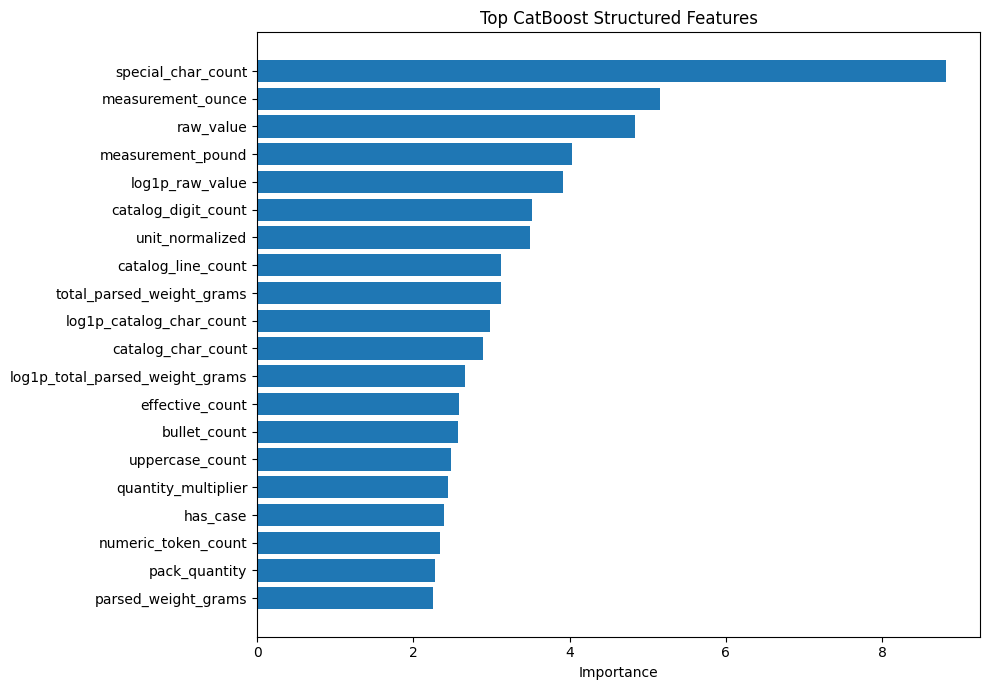

In [16]:
cat_importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': cat_log.get_feature_importance()
}).sort_values('importance', ascending=False)

display(cat_importance.head(30))
cat_importance.to_csv(METRICS_DIR / 'v05_catboost_feature_importance.csv', index=False)

top_imp = cat_importance.head(20)
plt.figure(figsize=(10, 7))
plt.barh(top_imp['feature'][::-1], top_imp['importance'][::-1])
plt.title('Top CatBoost Structured Features')
plt.xlabel('Importance')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'v05_catboost_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

## 17. Save Validation Predictions

In [17]:
out = valid_df[['sample_id', 'price']].copy()
out = out.rename(columns={'price': 'actual_price'})

for key, pred in predictions.items():
    out[key] = pred

out.to_csv(PREDICTIONS_DIR / 'v05_validation_predictions.csv', index=False)
display(out.head())

,sample_id,actual_price,cat_raw,cat_log,lgb_log,text_v03,text_cat_ensemble,text_lgb_ensemble,three_model_ensemble
0,55858,30.34,14.355747,13.569688,12.865055,10.066833,11.643117,11.605855,11.745766
1,292686,66.49,55.040601,32.581988,22.729983,35.531723,34.204342,28.490766,27.850679
2,9259,18.50,6.927705,7.232360,5.915879,8.624579,7.998081,7.134794,6.999359
3,254947,15.99,9.403791,10.563282,10.248695,14.171900,12.548022,12.014137,11.817977
4,271423,109.97,101.085985,51.234735,70.670544,28.844324,38.920009,51.848745,53.940056


## 18. Save Models and Ensemble Config

In [18]:
cat_raw.save_model(str(MODELS_DIR / 'catboost_raw.cbm'))
cat_log.save_model(str(MODELS_DIR / 'catboost_log.cbm'))
joblib.dump(lgb_log, MODELS_DIR / 'lightgbm_log.joblib')

ensemble_config = {
    'text_catboost': {
        'text_weight': best_text_w_cat,
        'catboost_weight': best_struct_w_cat,
    },
    'text_lightgbm': {
        'text_weight': best_text_w_lgb,
        'lightgbm_weight': best_struct_w_lgb,
    },
    'three_model': {
        'text_weight': float(best_three['text_weight']),
        'catboost_weight': float(best_three['catboost_weight']),
        'lightgbm_weight': float(best_three['lightgbm_weight']),
    }
}

with (MODELS_DIR / 'ensemble_config.json').open('w') as f:
    json.dump(ensemble_config, f, indent=2)

print('Saved models and ensemble configuration.')

Saved models and ensemble configuration.


## 19. Save Experiment Metadata

In [19]:
metadata = {
    'version': 'V0.5',
    'train_rows': int(len(train_df)),
    'validation_rows': int(len(valid_df)),
    'feature_count': int(len(feature_cols)),
    'best_model': str(leaderboard.loc[0, 'model']),
    'best_smape': float(leaderboard.loc[0, 'smape']),
    'v03_baseline_smape': 54.460909,
    'improvement_vs_v03_points': float(54.460909 - leaderboard.loc[0, 'smape']),
}

with (METRICS_DIR / 'v05_experiment_metadata.json').open('w') as f:
    json.dump(metadata, f, indent=2)

display(pd.Series(metadata, name='value').to_frame())

,value
version,V0.5
train_rows,60000
validation_rows,15000
feature_count,57
best_model,Text + LightGBM Ensemble
best_smape,52.373719
v03_baseline_smape,54.460909
improvement_vs_v03_points,2.08719


## 20. Final V0.5 Summary

In [20]:
print('=' * 88)
print('PRICEFUSION V0.5 — STRUCTURED & HYBRID MODELING COMPLETE')
print('=' * 88)
print(f'Train rows       : {len(train_df):,}')
print(f'Validation rows  : {len(valid_df):,}')
print(f'Feature count    : {len(feature_cols):,}')
print('-' * 88)
for _, row in leaderboard.iterrows():
    print(f"{row['model']:<48} SMAPE={row['smape']:.4f}%   MAE={row['mae']:.4f}")
print('-' * 88)
print(f"BEST MODEL : {leaderboard.loc[0, 'model']}")
print(f"BEST SMAPE : {leaderboard.loc[0, 'smape']:.4f}%")
print(f"V0.3 BEST  : 54.4609%")
print(f"GAIN       : {54.460909 - leaderboard.loc[0, 'smape']:.4f} SMAPE points")
print('=' * 88)
print('Next milestone: PriceFusion V0.6 — Transformer Text Embeddings')

PRICEFUSION V0.5 — STRUCTURED & HYBRID MODELING COMPLETE
Train rows       : 60,000
Validation rows  : 15,000
Feature count    : 57
----------------------------------------------------------------------------------------
Text + LightGBM Ensemble                         SMAPE=52.3737%   MAE=11.4903
Text + CatBoost + LightGBM Ensemble              SMAPE=52.3915%   MAE=11.4754
Text + CatBoost Ensemble                         SMAPE=53.2420%   MAE=11.7228
LightGBM Structured (Log Price)                  SMAPE=54.2350%   MAE=11.7875
V0.3 Word TF-IDF Log Baseline                    SMAPE=54.4609%   MAE=12.3154
CatBoost Structured (Raw Price)                  SMAPE=54.9348%   MAE=11.9114
CatBoost Structured (Log Price)                  SMAPE=55.6859%   MAE=12.0739
----------------------------------------------------------------------------------------
BEST MODEL : Text + LightGBM Ensemble
BEST SMAPE : 52.3737%
V0.3 BEST  : 54.4609%
GAIN       : 2.0872 SMAPE points
Next milestone: PriceFusion V0